In [44]:
from AnalysisDefinitions import AnalysisUltimate as AU
import matplotlib.pyplot as plt
import numpy as np

In [2]:
folder = "20251114_SPE_GN_137K" #requires a baseline file
ult = AU(h5_folder_path='DAQ_data/'+folder+'/',)

biases = list(ult.biases) #what biases to analyze
biases = sorted(list(biases))
num_pes = [5,   5,   5,   5,   5,   6,   6,   6,   6, ] #the number of peaks to fit, ordered by bias in increasing order
pes_dict = {biases[i+1]: num_pes[i] for i in range(len(biases)-1)} #create a dictinoary. Can be manual: keys are biases, data is number of peaks as int
lowerlim = [3.8, 3.8, 3.8, 3.9, 4.0, 4.1, 4.2, 4.4, 4.7] #in mV #the lowerlims to be used, ordered by bias in increasing order
lowerlimdict = {biases[i+1]:lowerlim[i]/1000 for i in range(len(lowerlim))} #create a dictionary. Can be manual: keys are biases, data is lowerlim as float
pe_center_guesses = None#[5.0, 5.2, 5.5, 5.9, 6.6, 7.0, 7.4, 7.8, 8.3] #centers of the first pe, ordered by bias in increasing order
if pe_center_guesses:
    centers = {biases[i+1]: [pe_center_guesses[i] * peak / 1000 for peak in range(1,num_pes[i]+1)] for i in range(len(biases)-1)} #create a dictinoary. Can be manual: keys are biases, data is list of centers guesses for the multigaussian
multicores = 6 #how many cores to use multiprocessing with. None for no multiprocessing
invC = 0.011547 #inverse capacitance of pream-shaper circuit, see Noah's calibration report
invCerr = 0.000098 #error on above term

#print(biases)
uplims = {v:-1 for v in biases}
uplims[20] = 0.063
poly = {v:True for v in biases}
poly[20] = False
proms = {v:0.002 for v in biases}
proms[20] = 0.008

In [3]:
ult.args_processwaveforms(do_filter=True,
                        prominence=proms,
                        condition = 'GN',
                        baseline_correct=True,
                        upper_limit=uplims,
                        poly_correct=poly)
#print(ult.processwaveforms_arguments)

In [4]:
ult.do_processwaveforms(temperature = 137,timeit=False,biases=biases)

Run Meta: {'CampaignIDNumber': '', 'RunName': 'SPE', 'RunNotes': 'GN 137K 405nm LED 2.72V 250Hz 10%DC', 'RunStart': '1763152059', 'User': 'Ed'}
filename: DAQ_data/20251114_SPE_GN_137K/Run_1763152059.hdf5, acquisition name: Acquisition_1763152112
reading all waveforms
0 read so far
1000 read so far
2000 read so far
3000 read so far
4000 read so far
5000 read so far
6000 read so far
7000 read so far
8000 read so far
9000 read so far
10000 read so far
11000 read so far
12000 read so far
13000 read so far
all  peaks: 2.32e-05 ± 3.53e-07
dark peaks: nan ± nan
LED  peaks: nan ± nan


c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret 

Run Meta: {'CampaignIDNumber': '', 'RunName': 'SPE', 'RunNotes': 'GN 137K 405nm LED 2.72V 250Hz 10%DC', 'RunStart': '1763150061', 'User': 'Ed'}
filename: DAQ_data/20251114_SPE_GN_137K/Run_1763150061.hdf5, acquisition name: Acquisition_1763150160
using polynomial baseline correction...
reading all waveforms
0 read so far
1000 read so far
2000 read so far
3000 read so far
4000 read so far
5000 read so far
6000 read so far
7000 read so far
8000 read so far
9000 read so far
10000 read so far
11000 read so far
12000 read so far
13000 read so far
all  peaks: 0.00296 ± 5.93e-06
dark peaks: 0.00177 ± 1.89e-06
LED  peaks: 0.00397 ± 9.99e-06
filename: DAQ_data/20251114_SPE_GN_137K/Run_1763150061.hdf5, acquisition name: Acquisition_1763150263
using polynomial baseline correction...
reading all waveforms
0 read so far
1000 read so far
2000 read so far
3000 read so far
4000 read so far
5000 read so far
6000 read so far
7000 read so far
8000 read so far
9000 read so far
10000 read so far
11000 read 

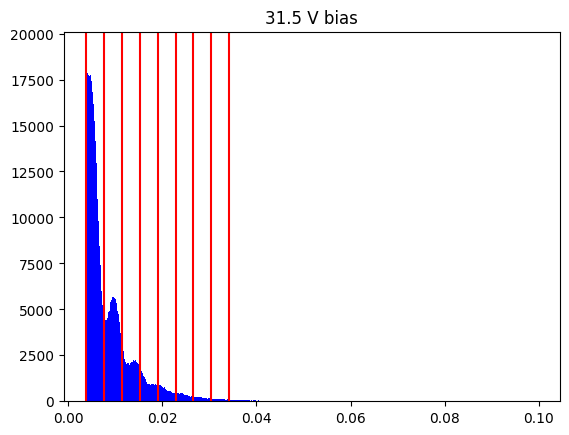

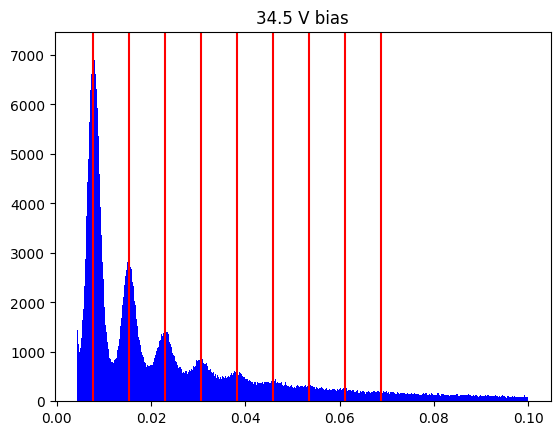

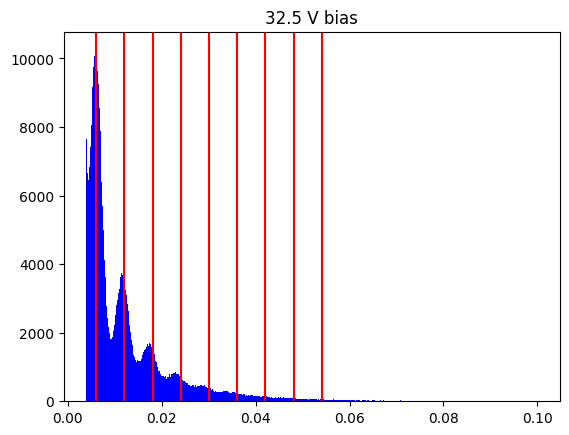

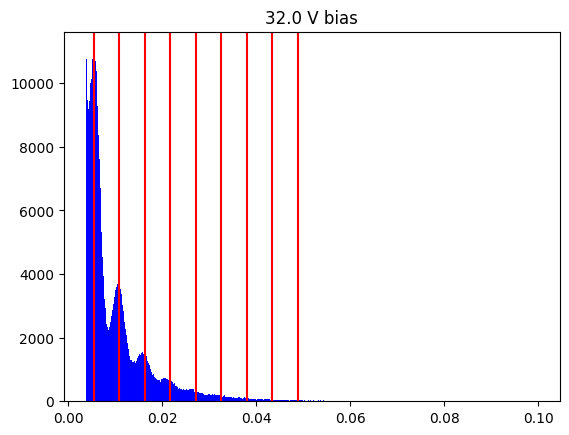

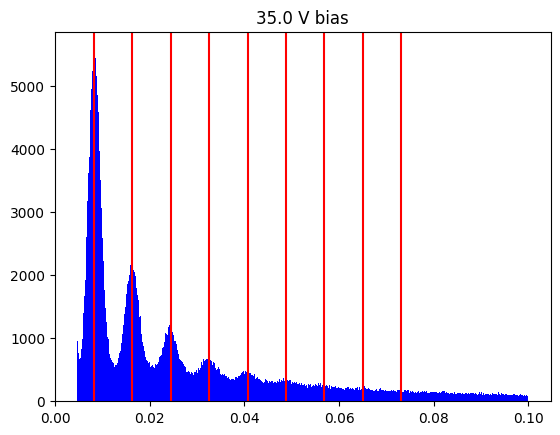

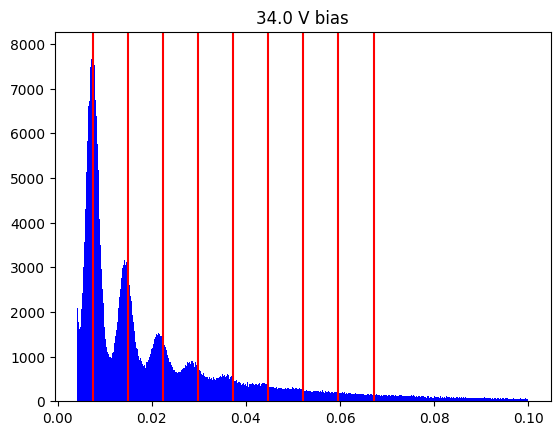

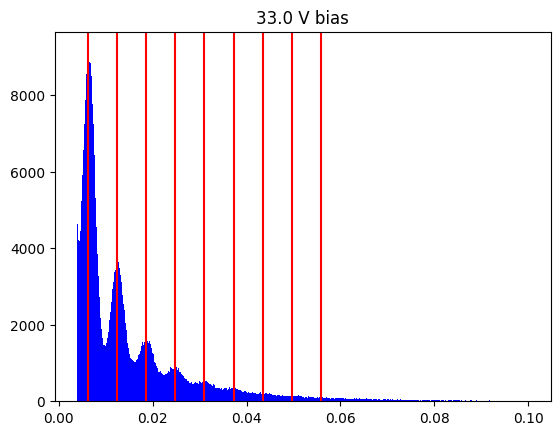

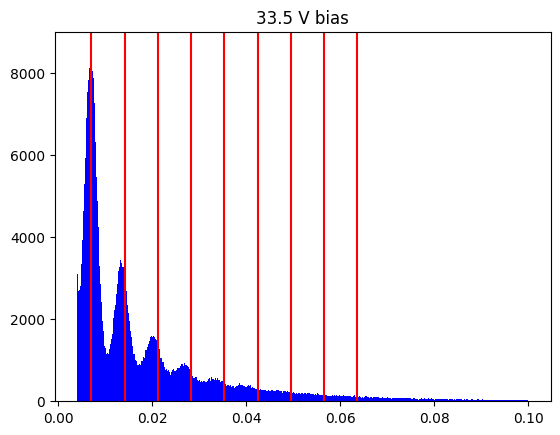

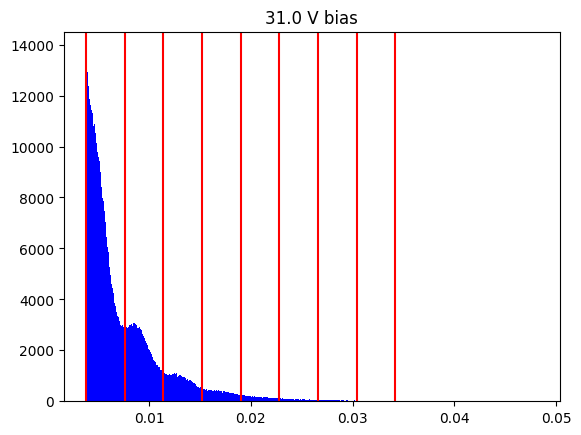

In [6]:
cutoffs = {}
for v in biases:
    if v <25:
        continue
    cutoffs[v] = (lowerlimdict[v], .1)
peak_ranges = {biases[i+1]: (1,num_pes[i]) for i in range(len(biases)-1)}

if not pe_center_guesses:
    centers = ult.guess_pe_locations(get_values=True,show_plots=True,cutoff=cutoffs)

ult.args_processhistograms(centers = centers, 
                        baseline_correct=True,
                        peaks='all',
                        cutoff=cutoffs,
                        background_linear=False,
                        peak_range=peak_ranges)

ult.create_processhistograms()


In [58]:
ult.histograms[31].centers = np.array(ult.histograms[31].centers)*1.1

In [85]:
peaks = 6
ult.histograms[31.5].numpeaks = peaks
ult.histograms[31.5].high_peak = peaks
ult.histograms[31.5].peak_range = (1,peaks)

In [86]:
ult.do_processhistograms(biases=[31.5])

CENTER GUESSES TO BE USED IN FIT:  [0.00456001 0.00912001 0.01368002 0.01824002 0.02280003 0.02736003]
WARNING! Fitted sigma 0.0012153046807759987 is less than baseline sigma 0.0012973962170588216!
WARNING! Fit failed to return a standard error on the peak locations and returned None! Setting std = 1
WARNING! Fit failed to return a standard error on the peak locations and returned None! Setting std = 1
WARNING! Fit failed to return a standard error on the peak locations and returned None! Setting std = 1
WARNING! Fit failed to return a standard error on the peak locations and returned None! Setting std = 1
WARNING! Fit failed to return a standard error on the peak locations and returned None! Setting std = 1
WARNING! Fit failed to return a standard error on the peak locations and returned None! Setting std = 1
sigma SNR: [np.float64(2.6567862772846853), np.float64(2.2307501248527877), np.float64(2.354858155477078), np.float64(1.4488817810345547), np.float64(1.991954008696943)]
CA at th

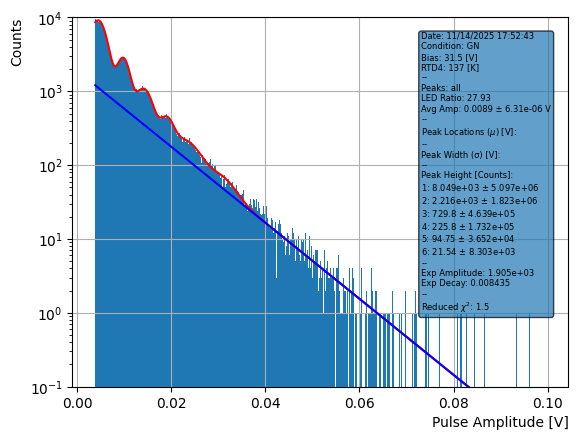

In [87]:
ult.histograms[31.5].plot_peak_histogram()

In [ ]:
for bias in biases:
    if bias < 25:
        continue
    ult.histograms[bias].plot_peak_histogram()

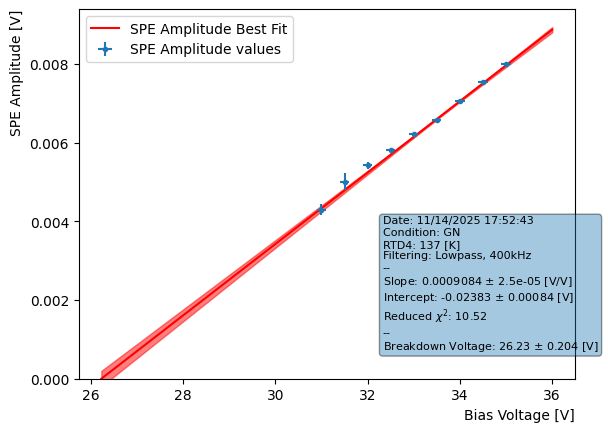

In [88]:
ult.do_spe_data(invC=invC,invC_err=invCerr,biases=biases)
ult.spe_data.plot_spe(in_ov=False,absolute=False)